# Importing libraires

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploring the malware dataset. <br/>
Malware Dataset:https://github.com/PacktPublishing/Mastering-Machine-Learning-for-Penetration-Testing/blob/master/Chapter03/MalwareData.csv.gz <br/>
<br/>
* 41,323 binaries (exe ,dll) - legitimate
* 96,724 malware files from virusshare.com


In [15]:
malData=pd.read_csv("/content/MalwareData.csv", sep="|", low_memory =True )

In [16]:
malData.head()

,Name,md5,Machine,SizeOfOptionalHeader,Characteristics,MajorLinkerVersion,MinorLinkerVersion,SizeOfCode,SizeOfInitializedData,SizeOfUninitializedData,...,ResourcesNb,ResourcesMeanEntropy,ResourcesMinEntropy,ResourcesMaxEntropy,ResourcesMeanSize,ResourcesMinSize,ResourcesMaxSize,LoadConfigurationSize,VersionInformationSize,legitimate
0,memtest.exe,631ea355665f28d4707448e442fbf5b8,332,224,258,9,0,361984,115712,0,...,4,3.262823,2.568844,3.537939,8797.000000,216,18032,0,16,1
1,ose.exe,9d10f99a6712e28f8acd5641e3a7ea6b,332,224,3330,9,0,130560,19968,0,...,2,4.250461,3.420744,5.080177,837.000000,518,1156,72,18,1
2,setup.exe,4d92f518527353c0db88a70fddcfd390,332,224,3330,9,0,517120,621568,0,...,11,4.426324,2.846449,5.271813,31102.272727,104,270376,72,18,1
3,DW20.EXE,a41e524f8d45f0074fd07805ff0c9b12,332,224,258,9,0,585728,369152,0,...,10,4.364291,2.669314,6.400720,1457.000000,90,4264,72,18,1
4,dwtrig20.exe,c87e561258f2f8650cef999bf643a731,332,224,258,9,0,294912,247296,0,...,2,4.306100,3.421598,5.190603,1074.500000,849,1300,72,18,1


In [17]:
malData.shape

(138047, 57)

In [18]:
malData.describe()

,Machine,SizeOfOptionalHeader,Characteristics,MajorLinkerVersion,MinorLinkerVersion,SizeOfCode,SizeOfInitializedData,SizeOfUninitializedData,AddressOfEntryPoint,BaseOfCode,...,ResourcesNb,ResourcesMeanEntropy,ResourcesMinEntropy,ResourcesMaxEntropy,ResourcesMeanSize,ResourcesMinSize,ResourcesMaxSize,LoadConfigurationSize,VersionInformationSize,legitimate
count,138047.000000,138047.000000,138047.000000,138047.000000,138047.000000,1.380470e+05,1.380470e+05,1.380470e+05,1.380470e+05,1.380470e+05,...,138047.000000,138047.000000,138047.000000,138047.000000,1.380470e+05,1.380470e+05,1.380470e+05,1.380470e+05,138047.000000,138047.000000
mean,4259.069274,225.845632,4444.145994,8.619774,3.819286,2.425956e+05,4.504867e+05,1.009525e+05,1.719561e+05,5.779845e+04,...,22.050700,4.000127,2.434541,5.521610,5.545093e+04,1.818082e+04,2.465903e+05,4.656750e+05,12.363115,0.299340
std,10880.347245,5.121399,8186.782524,4.088757,11.862675,5.754485e+06,2.101599e+07,1.635288e+07,3.430553e+06,5.527658e+06,...,136.494244,1.112981,0.815577,1.597403,7.799163e+06,6.502369e+06,2.124860e+07,2.608987e+07,6.798878,0.457971
min,332.000000,224.000000,2.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,332.000000,224.000000,258.000000,8.000000,0.000000,3.020800e+04,2.457600e+04,0.000000e+00,1.272100e+04,4.096000e+03,...,5.000000,3.458505,2.178748,4.828706,9.560000e+02,4.800000e+01,2.216000e+03,0.000000e+00,13.000000,0.000000
50%,332.000000,224.000000,258.000000,9.000000,0.000000,1.136640e+05,2.631680e+05,0.000000e+00,5.288300e+04,4.096000e+03,...,6.000000,3.729824,2.458492,5.317552,2.708154e+03,4.800000e+01,9.640000e+03,7.200000e+01,15.000000,0.000000
75%,332.000000,224.000000,8226.000000,10.000000,0.000000,1.203200e+05,3.850240e+05,0.000000e+00,6.157800e+04,4.096000e+03,...,13.000000,4.233051,2.696833,6.502239,6.558429e+03,1.320000e+02,2.378000e+04,7.200000e+01,16.000000,1.000000
max,34404.000000,352.000000,49551.000000,255.000000,255.000000,1.818587e+09,4.294966e+09,4.294941e+09,1.074484e+09,2.028711e+09,...,7694.000000,7.999723,7.999723,8.000000,2.415919e+09,2.415919e+09,4.294903e+09,4.294967e+09,26.000000,1.000000


In [19]:
legit= malData[0:41323].drop(["legitimate"], axis=1)
mal= malData[41323::].drop(["legitimate"], axis=1)
print("The shape of the legit dataset is: %s samples, %s features"%(legit.shape[0],legit.shape[1]))
print("The shape of the mal dataset is: %s samples, % s features" %(mal.shape[0],mal.shape[1]))

The shape of the legit dataset is: 41323 samples, 56 features
The shape of the mal dataset is: 96724 samples, 56 features


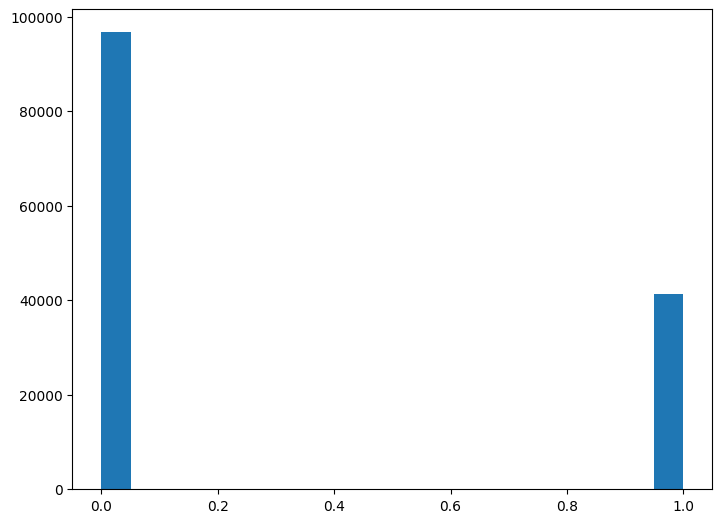

In [20]:
fig = plt.figure()
ax = fig.add_axes([0,0,1,1])
ax.hist(malData['legitimate'],20)
plt.show()

# Data Cleaning

In [21]:
y=malData['legitimate']
malData=malData.drop(['legitimate'],axis=1)

In [ ]:
# from sklearn.feature_selection import SelectKBest
# from sklearn.feature_selection import chi2
# X_new = SelectKBest(chi2, k=2).fit_transform(malData, y)
# X_new.shape

# Spliting the dataset into test and train

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(malData,y, test_size=0.2, random_state=42)

In [23]:
X_train.shape

(110437, 56)

# Model Building </br> </br>
## 1- Random Forest

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

# Create a LabelEncoder object for the 'Name' column
name_encoder = LabelEncoder()

# Fit the LabelEncoder on all unique values of 'Name' from both training and testing data
all_names = pd.concat([X_train['Name'], X_test['Name']]).unique()
name_encoder.fit(all_names)

# Transform the 'Name' column in both training and testing data
X_train['Name'] = name_encoder.transform(X_train['Name'])
X_test['Name'] = name_encoder.transform(X_test['Name'])

# Create an OrdinalEncoder object for other categorical columns
categorical_features = X_train.select_dtypes(include=['object']).columns
# Exclude 'Name' as it's already encoded
categorical_features = categorical_features.drop('Name', errors='ignore')
ordinal_encoder = OrdinalEncoder()

# Fit the OrdinalEncoder on all unique values of categorical features from both training and testing data
all_categorical_values = pd.concat([X_train[categorical_features], X_test[categorical_features]]).astype(str)
ordinal_encoder.fit(all_categorical_values)

# Transform the categorical features in both training and testing data
X_train[categorical_features] = ordinal_encoder.transform(X_train[categorical_features].astype(str))
X_test[categorical_features] = ordinal_encoder.transform(X_test[categorical_features].astype(str))

# Now you can proceed with fitting your model
clf = RandomForestClassifier(max_depth=2, random_state=0)
randomModel = clf.fit(X_train, y_train)

## Random forest Evaluation on test data

In [28]:
from sklearn.metrics import f1_score,accuracy_score,ConfusionMatrixDisplay,auc,confusion_matrix


In [29]:
#  Accuracy on the train dataset

train_pred=randomModel.predict(X_train)

accuracy_score(y_train,train_pred)

0.983954652879017

In [30]:
# Accuracy on the test dataset

prediction=randomModel.predict(X_test)

accuracy_score(y_test,prediction)

0.9847881202462876

In [31]:
f1_score(y_test, prediction)

0.9747231584015407

## Confusion matrix

Confusion matrix, without normalization
[[19092   158]
 [  262  8098]]


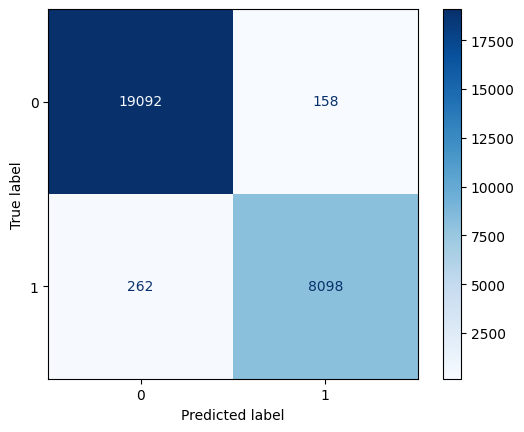

Normalized confusion matrix
[[19092   158]
 [  262  8098]]


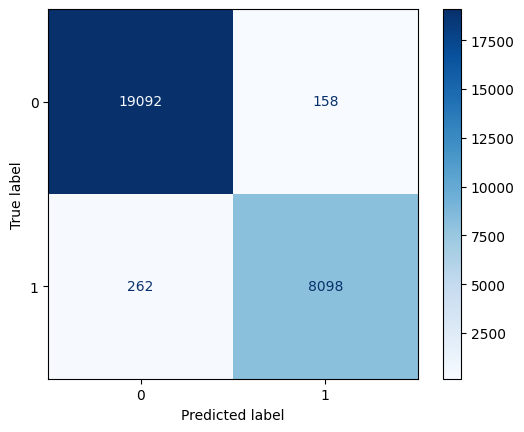

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
titles_options = [("Confusion matrix, without normalization", None),
                  ("Normalized confusion matrix", 'true')]
for title, normalize in titles_options:
    '''disp = plot_confusion_matrix(randomModel, X_test, y_test,
                                 display_labels='legitimate',
                                 cmap=plt.cm.Blues,
                                 normalize=normalize)'''
    cm = confusion_matrix(y_test, prediction, labels=clf.classes_)#, normalize='all')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=clf.classes_,)

    #disp.set_title(title)
    print(title)
    print(disp.confusion_matrix)
    #disp.plot()
    disp = disp.plot(cmap="Blues",values_format='')
    plt.show()

    '''cmn = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    fig, ax = plt.subplots(figsize=(10,10))
    sns.heatmap(cmn, annot=True, fmt='.2f', xticklabels=y_test, yticklabels=prediction)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show(block=False)'''

## 2 - logistic regression

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

clf = LogisticRegression(random_state=0)
logModel = clf.fit(X_train_scaled, y_train)

## Model Evaluation

In [47]:
# Accuracy on the train dataset

train_log= logModel.predict(X_train)

accuracy_score(y_train,train_log)

0.9230602062714489

In [48]:
# Accuracy on the test dataset

pred=logModel.predict(X_test)

accuracy_score(y_test,pred)

0.9237232886635277

In [49]:
f1_score(y_test, pred)

0.8575487012987013

## Confusion matrix

Confusion matrix, without normalization
[[19165    85]
 [ 2021  6339]]


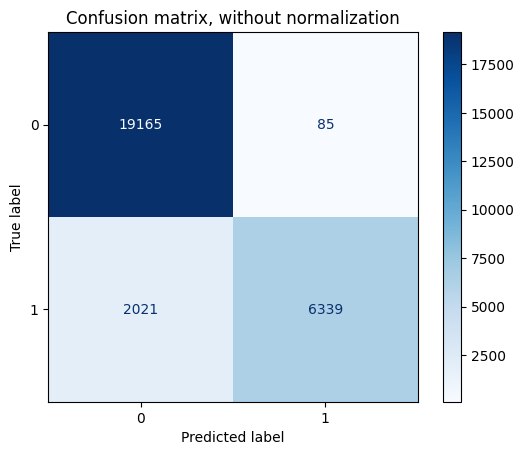

Normalized confusion matrix
[[0.99558442 0.00441558]
 [0.24174641 0.75825359]]


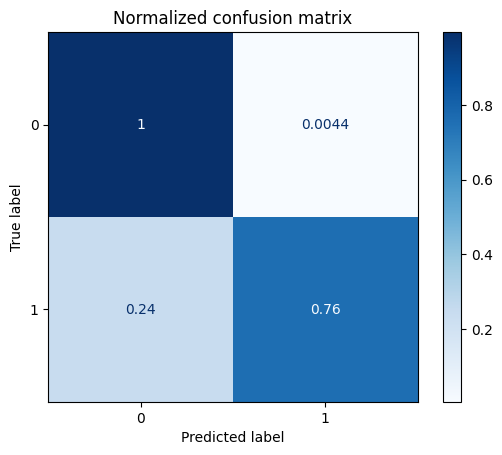

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

titles_options = [("Confusion matrix, without normalization", None),
                  ("Normalized confusion matrix", 'true')]
for title, normalize in titles_options:
    #disp = plot_confusion_matrix(logModel, X_test, y_test, # This line is causing the error
    #                             display_labels='legitimate',
    #                             cmap=plt.cm.Blues,
    #                             normalize=normalize)
    #disp.ax_.set_title(title)

    # Instead of using the deprecated 'plot_confusion_matrix',
    # use 'ConfusionMatrixDisplay' as follows:
    cm = confusion_matrix(y_test, logModel.predict(X_test), labels=logModel.classes_, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logModel.classes_)
    disp.plot(cmap=plt.cm.Blues)  # Set the colormap here
    disp.ax_.set_title(title)

    print(title)
    print(disp.confusion_matrix)

    plt.show()